# Lesson 8: Geometric Transformations

This lesson covers how to move, resize, and reshape images: flipping, cropping, rotating, and scaling, and then the more general hierarchy of 2D transformations &mdash; **Euclidean**, **similarity**, and **affine** &mdash; that those operations are all special cases of.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

## A test image with no symmetry

We draw a letter "F" because it has no rotational or mirror symmetry &mdash; every flip and rotation produces a visibly different result, which makes it easy to tell the transformations apart.

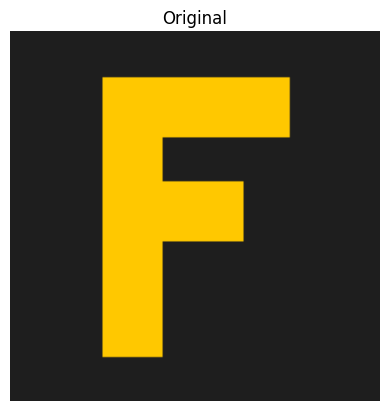

In [2]:
def make_f_image(size=160):
    img = np.zeros((size, size, 3), dtype=np.uint8)
    img[:] = (30, 30, 30)
    color = (255, 200, 0)
    cv2.rectangle(img, (40, 20), (65, 140), color, -1)   # vertical stroke
    cv2.rectangle(img, (40, 20), (120, 45), color, -1)   # top horizontal stroke
    cv2.rectangle(img, (40, 65), (100, 90), color, -1)   # middle horizontal stroke
    return img

img = make_f_image()
plt.imshow(img)
plt.title('Original')
plt.axis('off')
plt.show()

## Basic operations

### Flipping

`cv2.flip` mirrors an image: code `1` flips horizontally (left-right), `0` flips vertically (top-bottom), `-1` flips both.

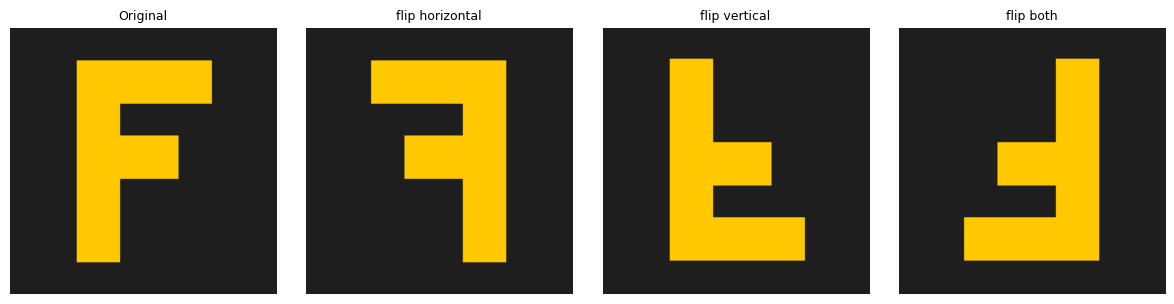

In [3]:
flip_h = cv2.flip(img, 1)
flip_v = cv2.flip(img, 0)
flip_hv = cv2.flip(img, -1)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, im, title in zip(axes, [img, flip_h, flip_v, flip_hv],
                          ['Original', 'flip horizontal', 'flip vertical', 'flip both']):
    ax.imshow(im)
    ax.set_title(title, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Cropping

Cropping is just array slicing &mdash; no OpenCV function needed. `image[y0:y1, x0:x1]` keeps rows `y0..y1` and columns `x0..x1`.

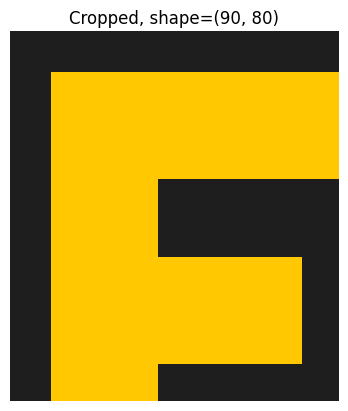

In [4]:
cropped = img[10:100, 30:110]

plt.imshow(cropped)
plt.title(f'Cropped, shape={cropped.shape[:2]}')
plt.axis('off')
plt.show()

### Scaling (resizing)

`cv2.resize` changes an image's dimensions, optionally with different factors for width and height. The ratio of width to height is the **aspect ratio**. Uniform scaling preserves shape (aspect ratio), non-uniform scaling stretches or squashes it.

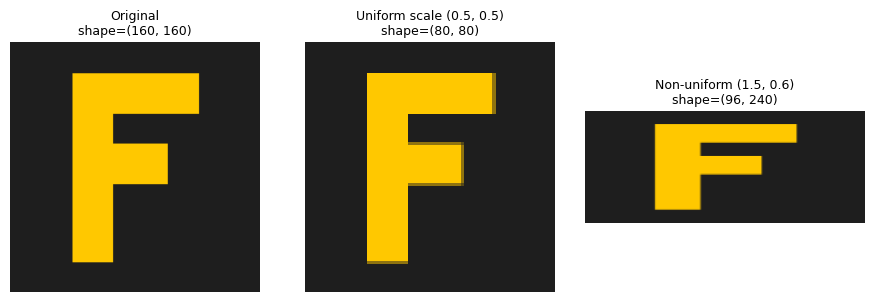

In [5]:
uniform = cv2.resize(img, None, fx=0.5, fy=0.5)
stretched = cv2.resize(img, None, fx=1.5, fy=0.6)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, title in zip(axes, [img, uniform, stretched],
                          ['Original', 'Uniform scale (0.5, 0.5)', 'Non-uniform (1.5, 0.6)']):
    ax.imshow(im)
    ax.set_title(f'{title}\nshape={im.shape[:2]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Rotating

`cv2.getRotationMatrix2D` builds a $2\times3$ matrix for rotating by an arbitrary angle around a chosen center, which `cv2.warpAffine` then applies to the image.

rotation matrix:
 [[  0.90630779   0.42261826 -26.3140839 ]
 [ -0.42261826   0.90630779  41.30483798]]


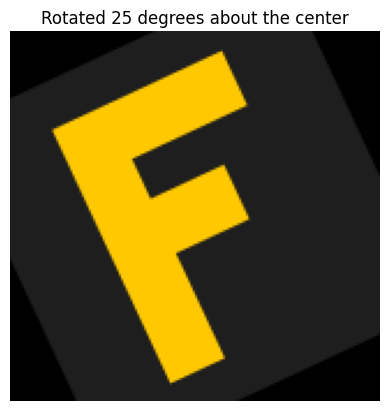

In [6]:
h, w = img.shape[:2]
center = (w / 2, h / 2)
M = cv2.getRotationMatrix2D(center, angle=25, scale=1.0)
print('rotation matrix:\n', M)

rotated = cv2.warpAffine(img, M, (w, h))

plt.imshow(rotated)
plt.title('Rotated 25 degrees about the center')
plt.axis('off')
plt.show()

## The transformation hierarchy

Flipping, rotating, scaling, and translating are all instances of a general $2\times3$ matrix transform

$$\begin{bmatrix}x'\\y'\end{bmatrix} = \begin{bmatrix}a & b\\c & d\end{bmatrix}\begin{bmatrix}x\\y\end{bmatrix} + \begin{bmatrix}t_x\\t_y\end{bmatrix}$$

applied with `cv2.warpAffine`. Restricting the $2\times2$ part in different ways gives a nested family of transformations, from most to least restrictive:

| Transform | Free parameters | Matrix form | Preserves |
|---|---|---|---|
| **Euclidean (rigid)** | rotation $\theta$, translation $(t_x,t_y)$ | $\begin{bmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{bmatrix}$ | lengths, angles |
| **Similarity** | + uniform scale $s$ | $s\begin{bmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{bmatrix}$ | angles, ratios of lengths |
| **Affine** | any invertible $2\times2$ matrix | $\begin{bmatrix}a & b\\c & d\end{bmatrix}$ | parallelism, ratios along a line |

Two different things change as you go down the table, in opposite directions. The *set of allowed transforms* grows: every Euclidean transform is a special case of a similarity transform (just $s=1$), and every similarity transform is a special case of an affine transform (just a rotation-and-scale matrix instead of an arbitrary one) &mdash; so each row's transforms are a superset of the row above's. In exchange for that extra flexibility, the *properties guaranteed to survive* shrink: Euclidean preserves both lengths and angles; similarity gives up preserving lengths themselves (only their ratios survive); affine gives up angles too. Affine transforms are the most general of the three: they can shear a square into a parallelogram, something neither Euclidean nor similarity transforms can do.

### Seeing the difference on a unit square

The clearest way to see what each transform can and cannot do is to watch what happens to a simple square.

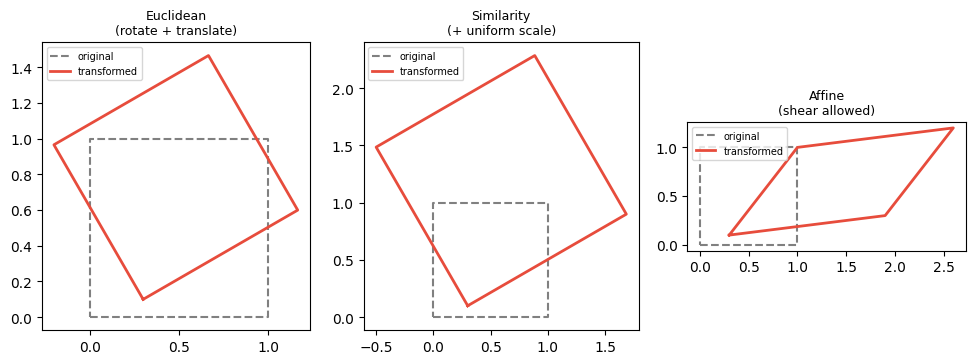

In [7]:
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]], dtype=np.float64)

def apply_2x2(pts, A, t=(0, 0)):
    return pts @ A.T + np.array(t)

theta = np.radians(30)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])

euclidean_sq  = apply_2x2(square, R, t=(0.3, 0.1))
similarity_sq = apply_2x2(square, 1.6 * R, t=(0.3, 0.1))
affine_sq     = apply_2x2(square, np.array([[1.6, 0.7], [0.2, 0.9]]), t=(0.3, 0.1))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, pts, title in zip(
    axes,
    [euclidean_sq, similarity_sq, affine_sq],
    ['Euclidean\n(rotate + translate)', 'Similarity\n(+ uniform scale)', 'Affine\n(shear allowed)'],
):
    ax.plot(*square.T, '--', color='gray', label='original')
    ax.plot(*pts.T, color='#e74c3c', linewidth=2, label='transformed')
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=7, loc='upper left')
plt.tight_layout()
plt.show()

Only the affine square stops looking like a (possibly resized) square &mdash; its corners are no longer 90 degrees, because affine transforms allow shear. All three keep opposite sides parallel.  (The more general projective transforms, e.g., camera perspective, are covered in Lesson 24).

This animation shows the square morphing continuously to its final transform and back. The Euclidean square stays rigid, the similarity square grows but remains "square-shaped," and the affine square shears its right angles into a parallelogram.

<img src="https://github.com/sbirchfield/sbirchfield.github.io/blob/main/cvintro/animations/transform_hierarchy_demo.gif?raw=1" alt="Animated morph of a unit square from identity to a Euclidean, similarity, and affine transform, showing which properties (lengths, angles, parallelism) survive each" style="display: block; margin: 0 auto; max-width: 900px;">

### Fitting an affine transform from point correspondences

In practice we often don't know the transform matrix directly. Example: a flat object was photographed *at an angle* (or a scan came out skewed), and we want to undo the distortion.  This requires us to identify a few landmark points in both the skewed photo and where they *should* be in a canonical, front-on view. `cv2.getAffineTransform` takes 3 such point correspondences (the minimum needed to determine all 6 affine parameters) and returns the matrix that maps one set onto the other — solve for the warped-to-canonical direction, and applying it *rectifies* the photo.

mean abs pixel error, rectified vs. true original: 3.14


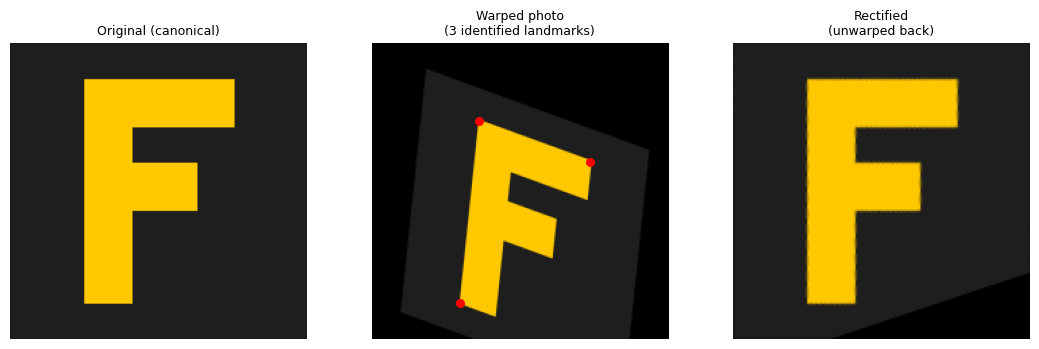

In [8]:
canvas_size = (w + 60, h + 60)

# simulate a photo taken at an angle: apply a KNOWN affine warp (rotation + shear + scale)
# -- in a real application this warp is unknown; we only ever get to see `warped` below
theta = np.radians(20)
R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
shear = np.array([[1, 0.25], [0, 1]])
A_true = R @ shear * 1.1
t_true = np.array([40, 20])
M_true = np.hstack([A_true, t_true.reshape(2, 1)])

warped = cv2.warpAffine(img, M_true, canvas_size)

# 3 landmarks we can identify in BOTH images (e.g. by clicking on the F's outer corners)
canonical_pts = np.float32([[40, 20], [120, 20], [40, 140]])
warped_pts = ((A_true @ canonical_pts.T).T + t_true).astype(np.float32)  # where those 3 points ended up

# solve for the warped -> canonical transform, then apply it to rectify the whole photo
M_recovered = cv2.getAffineTransform(warped_pts, canonical_pts)
rectified = cv2.warpAffine(warped, M_recovered, (w, h))

pixel_error = np.abs(rectified.astype(int) - img.astype(int)).mean()
print('mean abs pixel error, rectified vs. true original:', round(pixel_error, 2))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].imshow(img)
axes[0].set_title('Original (canonical)', fontsize=9)
axes[1].imshow(warped)
for p in warped_pts:
    axes[1].scatter(*p, c='red', s=30)
axes[1].set_title('Warped photo\n(3 identified landmarks)', fontsize=9)
axes[2].imshow(rectified)
axes[2].set_title('Rectified\n(unwarped back)', fontsize=9)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

This animation shows the warp distorting the photo, then the recovered transform undoing it, indicating the 3 landmark points throughout. The side panel highlights an important asymmetry: stage 1 applies a matrix directly (which is generally unknown), while stage 2 must first *solve* for that matrix from the 3 point correspondences before it can apply it.

<img src="https://github.com/sbirchfield/sbirchfield.github.io/blob/main/cvintro/animations/affine_rectify_demo.gif?raw=1" alt="Animated warp-then-rectify sequence, showing a photo being distorted by a known affine warp and then recovered using 3 tracked landmark points, with a side panel explaining the asymmetry between applying a known warp and solving for an unknown one" style="display: block; margin: 0 auto; max-width: 680px;">

### Exercises

1. `cv2.flip` is not part of the affine family we wrote in matrix form above (rotation matrices $R$ always have determinant $+1$). What determinant does a flip's $2\times2$ matrix have? Construct the $2\times2$ matrix for `flip(1)` and check.
2. Build a similarity transform matrix with $s=1$ and confirm it matches a pure Euclidean transform &mdash; i.e. similarity is a strict generalization of Euclidean, not a different family.
3. Modify the affine matrix in the unit-square example so that opposite sides are *not* parallel. What has to break for that to happen? (Hint: this is exactly the boundary that separates affine from projective transforms.)

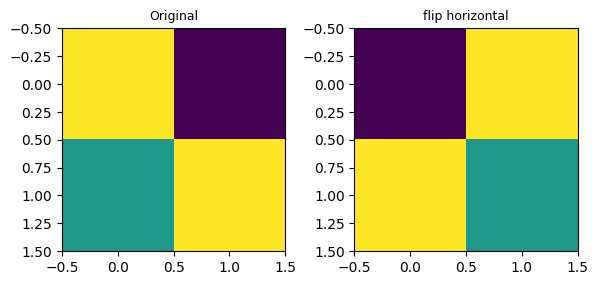

In [13]:
# Exercise 1
flip_h = cv2.flip(R, 1)
fig, axes = plt.subplots(1, 2, figsize=(6,9))
for ax, im, title in zip(axes, [R, flip_h], ['Original', 'flip horizontal']):
    ax.imshow(im)
    ax.set_title(title, fontsize=9)
    ax.axis('on')
plt.tight_layout()
plt.show()

In [15]:
print(np.linalg.det(R))
print(np.linalg.det(flip_h))

1.0
-1.0


In [23]:
print(R)

[[ 0.93969262 -0.34202014]
 [ 0.34202014  0.93969262]]


In [20]:
# Exercise 2
similarity_sq1 = apply_2x2(square, 1.0 * R, t=(0.3, 0.1))

np.isclose(similarity_sq1, euclidean_sq)

array([[ True,  True],
       [False, False],
       [False, False],
       [False, False],
       [ True,  True]])

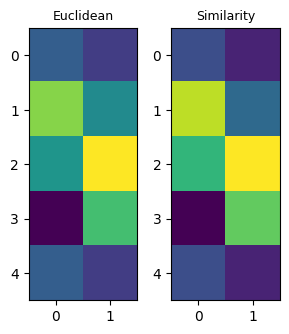

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(3,4))
for ax, im, title in zip(axes, [euclidean_sq, similarity_sq1], ['Euclidean', 'Similarity']):
    ax.imshow(im)
    ax.set_title(title, fontsize=9)
    ax.axis('on')
plt.tight_layout()
plt.show()

### Exercise 1: Horizontal Flip Matrix and Determinant

A horizontal flip maps $(x, y)$ to $(-x, y)$.
In matrix form, this is:
$$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} -1 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix}$$

Let's construct this matrix and check its determinant.

In [25]:
# Construct the 2x2 horizontal flip matrix
F_h = np.array([[-1, 0],
                [ 0, 1]], dtype=np.float64)

det_F_h = np.linalg.det(F_h)
print("2D Horizontal Flip Matrix:\n", F_h)
print("\nDeterminant of the flip matrix:", det_F_h)

2D Horizontal Flip Matrix:
 [[-1.  0.]
 [ 0.  1.]]

Determinant of the flip matrix: -1.0


### Exercise 2: Similarity Transform with $s=1$ vs. Euclidean Transform

Let's verify that a similarity transform with scale $s=1$ matches the Euclidean transform exactly, and visualize them side-by-side using lines.

Are similarity (s=1) and Euclidean coordinates identical? True


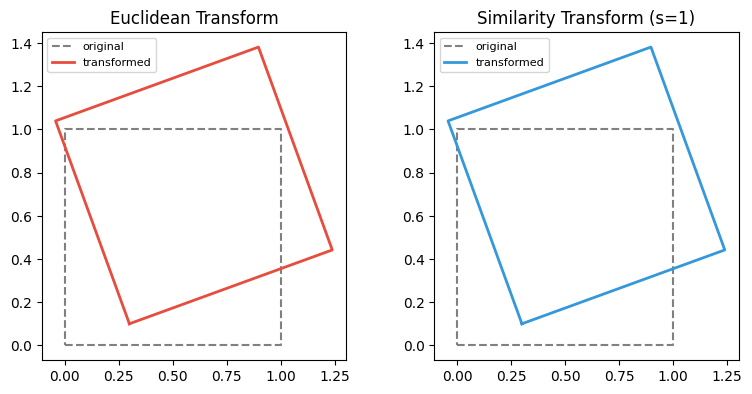

In [26]:
# Calculate both square transformations
euclidean_sq = apply_2x2(square, R, t=(0.3, 0.1))
similarity_sq1 = apply_2x2(square, 1.0 * R, t=(0.3, 0.1))

# Confirm they are element-wise identical/extremely close
all_close = np.allclose(similarity_sq1, euclidean_sq)
print("Are similarity (s=1) and Euclidean coordinates identical?", all_close)

# Correctly plot the shapes
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].plot(*square.T, '--', color='gray', label='original')
axes[0].plot(*euclidean_sq.T, color='#e74c3c', linewidth=2, label='transformed')
axes[0].set_aspect('equal')
axes[0].set_title('Euclidean Transform')
axes[0].legend(fontsize=8)

axes[1].plot(*square.T, '--', color='gray', label='original')
axes[1].plot(*similarity_sq1.T, color='#3498db', linewidth=2, label='transformed')
axes[1].set_aspect('equal')
axes[1].set_title('Similarity Transform (s=1)')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Exercise 3: Projective Transform (Non-Parallel Sides)

To make opposite sides of our square non-parallel, we must use a **projective transformation** (homography). Instead of a $2 \times 2$ matrix applied via multiplication and translation, a projective transformation uses a $3 \times 3$ matrix on homogeneous coordinates $[x, y, 1]^T$:

$$\begin{bmatrix} x' \\ y' \\ w' \end{bmatrix} = \begin{bmatrix} h_{11} & h_{12} & h_{13} \\ h_{21} & h_{22} & h_{23} \\ h_{31} & h_{32} & 1 \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

Where the actual coordinates are obtained by dividing by the homogeneous scale factor $w'$:
$$x_{final} = \frac{x'}{w'}, \quad y_{final} = \frac{y'}{w'}$$

If the bottom row coefficients ($h_{31}$ and $h_{32}$) are non-zero, the divisor changes depending on position, which breaks parallelism.

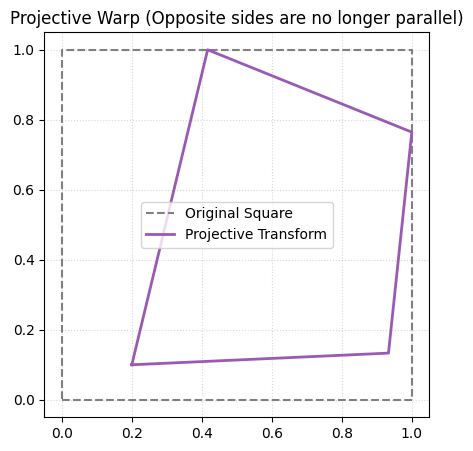

In [27]:
# Define homogeneous coordinates for the square vertices [x, y, 1]
square_homg = np.hstack([square, np.ones((square.shape[0], 1))])

# Construct a 3x3 projective transformation matrix (Homography)
# The bottom row [0.5, 0.2, 1.0] breaks the affine constraint of parallel lines
H = np.array([
    [1.2, 0.3, 0.2],
    [0.1, 1.1, 0.1],
    [0.5, 0.2, 1.0]
])

# Apply the transformation
projected_homg = square_homg @ H.T

# Normalize back from homogeneous coordinates to 2D coordinates (divide by w)
projected_sq = projected_homg[:, :2] / projected_homg[:, 2:3]

# Visualize the result
plt.figure(figsize=(5, 5))
plt.plot(*square.T, '--', color='gray', label='Original Square')
plt.plot(*projected_sq.T, color='#9b59b6', linewidth=2, label='Projective Transform')
plt.set_cmap('gray')
plt.gca().set_aspect('equal')
plt.title('Projective Warp (Opposite sides are no longer parallel)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()